# 1. Data preparation

First analysis to check that the data is complete and stuff

All notebooks load data using `experiment_data.py`, which recomputes every value
from the raw files in `data/experiments/llm_routing/`:

- `energibridge.csv`: EnergiBridge samples, every 200ms
- `queries.csv`: one row per question

Notebooks:
1 data preparation
2 exploration
3 hypothesis tests (RQ1, RQ3, η)
4 accuracy and the energy-accuracy trade-off (RQ2).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

import experiment_data as data
import stats
import style

style.apply()
pd.set_option("display.precision", 3)
runs = data.load_runs()

## 1.1 Completeness

Expected: 90 runs, 30 per strategy, each answering the same 500 questions, with no missing/negative values.

In [2]:
print(runs.groupby("strategy", observed=True).size().to_string())
print("questions per run:", runs["n_queries"].unique())
print("missing values:", int(runs.isna().sum().sum()))
energy_columns = ["cpu_energy_j", "gpu0_energy_j", "gpu1_energy_j", "energy_j"]
print("non-positive energies:", int((runs[energy_columns] <= 0).sum().sum()))

strategy
S    30
L    30
R    30
questions per run: [500]
missing values: 0
non-positive energies: 0


## 1.2 Experiment timeline

Runs in chronological order. The gap includes server start-up, warm-up, the measured run and
the 60s cooldown.

In [3]:
first, last = runs["start"].iloc[0], runs["start"].iloc[-1]
print(f"first run {first:%Y-%m-%d %H:%M}, last run {last:%H:%M}, span {last - first}")

gaps = runs["start"].diff().dt.total_seconds()
print(gaps.describe().round(1).to_string())

runs[["order", "run_id", "strategy", "start"]].head()

first run 2026-10-19 19:12, last run 09:21, span 0 days 14:08:36.247000
count     89.0
mean     572.1
std      119.5
min      411.8
25%      415.8
50%      605.5
75%      695.6
max      701.0


,order,run_id,strategy,start
0,0,run_0_repetition_22,S,2026-10-19 19:12:46.275
1,1,run_1_repetition_21,L,2026-10-19 19:19:39.734
2,2,run_2_repetition_10,R,2026-10-19 19:31:20.726
3,3,run_0_repetition_12,S,2026-10-19 19:41:25.690
4,4,run_2_repetition_28,R,2026-10-19 19:48:23.498


## 1.3 Sampling interval

The energy formula uses the actual time between samples, so discrepancies are fine (to a point)

In [4]:
runs[["sample_interval_median_ms", "sample_interval_max_ms"]].describe().round(1)

,sample_interval_median_ms,sample_interval_max_ms
count,90.0,90.0
mean,200.0,209.5
std,0.0,1.2
min,200.0,201.0
25%,200.0,209.0
50%,200.0,210.0
75%,200.0,210.0
max,200.0,210.0


## 1.4 Our energy matches Experiment Runner's run table

Experiment Runner computed energy during the experiment (`RunnerConfig.populate_run_data`).
The analysis also grabs it, from the raw files. Check if both are equal:

In [5]:
run_table = pd.read_csv(data.EXPERIMENT_DIR / "run_table.csv").set_index("__run_id")

ours = runs.set_index("run_id")["energy_j"]
theirs = run_table["cpu_energy_j"] + run_table["gpu_energy_j"]

print("largest relative difference:", ((ours - theirs[ours.index]) / ours).abs().max())

largest relative difference: 2.120323043117991e-16


## 1.5 Determinism

Report Section 4.4 says each repetition strategy produces exactly the same answers,
and that no answer reaches the 512-token limit.

In [6]:
mismatches = {}
for i, strategy in enumerate(data.STRATEGIES):
    first = data.load_queries(f"run_{i}_repetition_0")
    others = runs.loc[runs["strategy"] == strategy, "run_id"]
    mismatches[strategy] = sum(
        not data.load_queries(run_id)[["model", "correct", "completion_tokens", "response"]]
            .equals(first[["model", "correct", "completion_tokens", "response"]])
        for run_id in others)
print("repetitions differing from repetition 0:", mismatches)
longest = max(data.load_queries(f"run_{i}_repetition_0")["completion_tokens"].max() for i in range(3))
print("longest answer:", longest, "tokens (limit 512)")

repetitions differing from repetition 0: {'S': 0, 'L': 0, 'R': 0}
longest answer: 512 tokens (limit 512)


## 1.6 Where the energy goes

Energy per component, as mean J per run. GPU 0 under S, GPU 1 under L.

In [7]:
components = runs.groupby("strategy", observed=True)[["cpu_energy_j", "gpu0_energy_j", "gpu1_energy_j"]].mean()
shares = 100 * components.div(components.sum(axis=1), axis=0)
display(components.round(0).join(shares.add_suffix(" %").round(1)))

mean_time = runs.groupby("strategy", observed=True)["time_s"].mean()

power = components.div(mean_time, axis=0).rename(columns=lambda c: c.replace("energy_j", "power_w"))
power.round(1)

,cpu_energy_j,gpu0_energy_j,gpu1_energy_j,cpu_energy_j %,gpu0_energy_j %,gpu1_energy_j %
strategy,,,,,,
S,34160.0,4739.0,37363.0,44.8,6.2,49.0
L,61928.0,79342.0,7365.0,41.7,53.4,5.0
R,53806.0,57309.0,26680.0,39.0,41.6,19.4


,cpu_power_w,gpu0_power_w,gpu1_power_w
strategy,,,
S,99.4,13.8,108.7
L,98.8,126.6,11.8
R,100.4,107.0,49.8


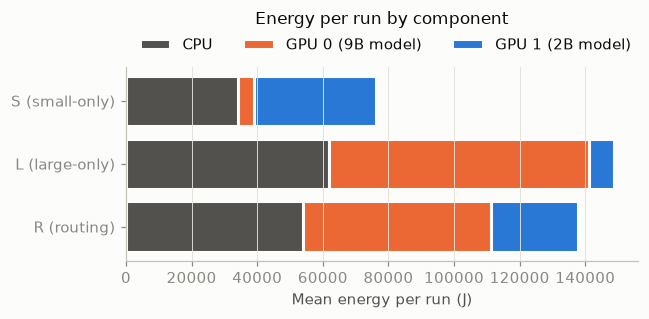

In [8]:
fig, ax = plt.subplots(figsize=(6, 3))

left = pd.Series(0.0, index=components.index)

for column, name, shade in [("cpu_energy_j", "CPU", style.SECONDARY),
                            ("gpu0_energy_j", "GPU 0 (9B model)", style.COLORS["L"]),
                            ("gpu1_energy_j", "GPU 1 (2B model)", style.COLORS["S"])]:
    ax.barh([style.label(s) for s in components.index], components[column], left=left,
            color=shade, edgecolor="#fcfcfb", linewidth=2, label=name)
    left += components[column]
    
ax.set_xlabel("Mean energy per run (J)")
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.legend(ncols=3, loc="lower left", bbox_to_anchor=(0, 1.0))
ax.set_title("Energy per run by component", pad=28)

plt.tight_layout()

**Notes**

- **Completeness:** all checks pass.
- **Determinism:** repetitions are exact copies in answers and tokens. Accuracy has no run-to-run difference.
- **The CPU's share is large:** about 99–100 W consistently, or 39–45% of total energy. The CPU should
  barely be busy during GPU inference, so this is likely mostly the CPU baseline.
  It scales with run *time*, which is why longer strategies pay for it.
- **The idle GPU costs something too:** about 12–14 W. Should be included because a host offering both models
  would want to keep both GPUs turned on.
- **The 2B model's GPU costs more during R than idling.** It averages 50 W under R while
  busy 20% of the time, compared to 12–14 W when it has no model. More analysis later (notebook 4).